# Clasificación calibrada de señales de tránsito de Kepler
### Red multirrama con un codificador por tránsito con atención · Curso de Deep Learning

**Juan Sebastian Higuita Riascos** · Especialización en Inteligencia Artificial, Universidad Nacional de Colombia

Este notebook **no entrena nada**: lee las predicciones y tablas que dejaron los scripts del repositorio (`resultados/dl/`) y las dibuja. Cada cifra que aparece aquí sale de esos archivos.

**Cómo leerlo.** Cada sección responde una pregunta. Al final hay un **explorador interactivo** para mirar cualquier señal: sus datos, lo que opinó cada rama y qué tan seguro quedó el sistema.

| Sección | Pregunta |
|---|---|
| 1 | ¿Qué datos hay y cómo se ven? |
| 2 | ¿Cuál es el listón que hay que superar? |
| 3 | **P1.** ¿Qué arquitectura lee mejor la señal de tránsito? |
| 4 | ¿A qué tránsitos presta atención el modelo? |
| 5 | **P2.** ¿Cuánto mejora la decisión al fusionar las cuatro ramas? |
| 6 | **P3.** ¿Se puede confiar en las probabilidades? |
| 7 | Explorador interactivo |
| 8 | Veredicto de las hipótesis y limitaciones |

> **Qué es de este curso y qué no.** Las ramas 1 (vistas), 2 (tránsitos) y 4 (escalares), la fusión y la calibración son de este curso. La **rama 3 (imagen)** es el codificador **v0 de la demo**, código anterior a los cursos, usado congelado: no es un aporte de este trabajo.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "protocolo.json").is_file())
R, T = RAIZ / "resultados" / "dl", RAIZ / "resultados" / "dl" / "tablas"
leer = lambda ruta: json.loads(Path(ruta).read_text(encoding="utf-8"))
CLASES = ["Planeta", "Falso positivo", "Sin señal"]
COL = {"planeta": "#1f77b4", "fp": "#d62728", "nada": "#7f7f7f", "curso": "#6a3d9a", "base": "#9e9e9e", "demo": "#e08a00"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})

ej = pd.read_csv(RAIZ / "compartido" / "ejemplos.csv")
D = dict(np.load(RAIZ / "data" / "dataset_temporal.npz", allow_pickle=False))
ids = D["id_ejemplo"].astype(str)
tabla = ej.set_index("id_ejemplo").loc[ids].reset_index()
y = tabla["clase"].to_numpy()
pos = {i: j for j, i in enumerate(ids)}

def pred(carpeta, semilla=0, clave="p_prueba"):
    """Predicciones fuera de muestra alineadas con `ids` (NaN si el experimento no tiene ese ejemplo)."""
    d = np.load(R / carpeta / f"pred_semilla{semilla}.npz", allow_pickle=False)
    p = np.full((len(ids), 3), np.nan)
    p[[pos[i] for i in d["id_ejemplo"].astype(str)]] = d[clave]
    return p

def bosque(ax, etiquetas, est, lo, hi, colores=None, ref=None):
    """Gráfico de puntos con intervalos de confianza del 95 %."""
    yy = np.arange(len(etiquetas))[::-1]
    colores = colores or ["#333"] * len(etiquetas)
    for a, e, l, h, c in zip(yy, est, lo, hi, colores):
        ax.plot([l, h], [a, a], color=c, lw=2.2, solid_capstyle="round"); ax.plot(e, a, "o", color=c, ms=6)
        ax.text(h, a, f"  {e:.3f}", va="center", fontsize=8.5, color=c)
    ax.set_yticks(yy); ax.set_yticklabels(etiquetas)
    if ref is not None: ax.axvline(ref, color="k", lw=0.8, ls="--")
    ax.grid(axis="y", visible=False)

print(f"{len(ids)} ejemplos · {tabla.kepid.nunique()} estrellas · clases:", dict(zip(CLASES, np.bincount(y))))

490 ejemplos · 245 estrellas · clases: {'Planeta': np.int64(130), 'Falso positivo': np.int64(115), 'Sin señal': np.int64(245)}


## 1 · Los datos

Kepler midió el brillo de cada estrella cada 30 minutos durante 4 años. Un planeta que pasa por delante produce una **caída periódica**. Pero hay impostores: estrellas dobles que se eclipsan, estrellas vecinas y fallas del instrumento.

Cada señal (KOI) da **dos ejemplos**: el tránsito real (*planeta* o *falso positivo*, según el catálogo DR25 de NASA) y la misma estrella en una época desplazada un cuarto de órbita, con la señal real oculta (*sin señal*).

De cada curva de luz salen **tres formas de mirarla**:

- **Vista plegada (rama 1):** todos los tránsitos apilados y promediados. Limpia el ruido, pero borra las diferencias entre un tránsito y otro.
- **Tránsitos uno por uno (rama 2):** hasta 32 ventanas individuales. Permite ver si un tránsito no se parece a los demás.
- **Escalares (rama 4):** periodo, duración, profundidad, relación señal/ruido y desplazamiento de centroide.

Todo está en **unidades de profundidad**: un tránsito real vale cerca de −1.

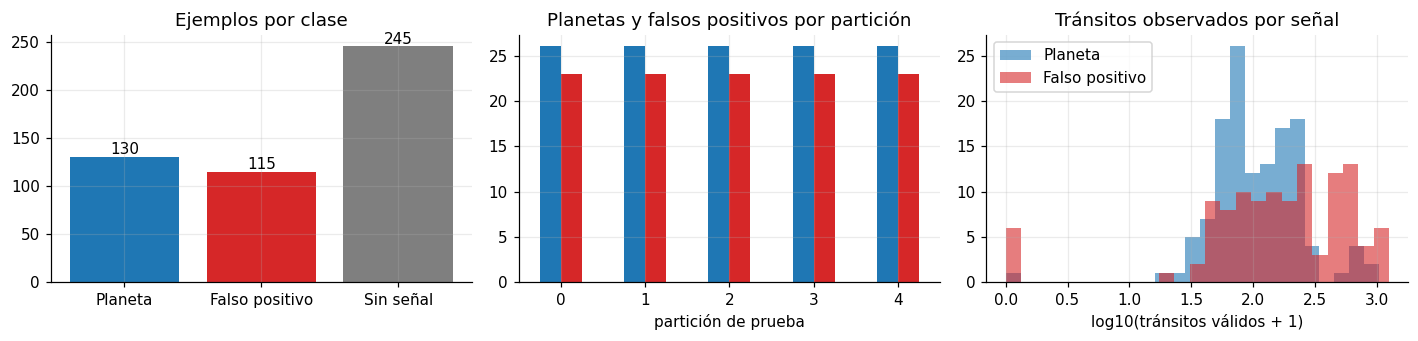

Ejemplos disponibles: {'rama 1 (vistas)': 467, 'rama 2 (tránsitos)': 471} de 490


In [2]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
c = np.bincount(y); ax[0].bar(CLASES, c, color=[COL["planeta"], COL["fp"], COL["nada"]])
for i, v in enumerate(c): ax[0].text(i, v + 3, str(v), ha="center")
ax[0].set_title("Ejemplos por clase")
cont = tabla[tabla.tipo == "transito"].groupby(["particion", "clase"]).size().unstack()
cont.plot.bar(ax=ax[1], color=[COL["planeta"], COL["fp"]], legend=False, rot=0); ax[1].set_title("Planetas y falsos positivos por partición"); ax[1].set_xlabel("partición de prueba")
real = y < 2
for cls, col, nom in ((0, COL["planeta"], "Planeta"), (1, COL["fp"], "Falso positivo")):
    ax[2].hist(np.log10(D["n_transitos_validos"][y == cls] + 1), bins=25, alpha=0.6, color=col, label=nom)
ax[2].set_xlabel("log10(tránsitos válidos + 1)"); ax[2].set_title("Tránsitos observados por señal"); ax[2].legend()
plt.tight_layout(); plt.show()
disp = pd.DataFrame({"rama 1 (vistas)": D["disponible_vistas"], "rama 2 (tránsitos)": D["disponible_transitos"]}).sum()
print("Ejemplos disponibles:", disp.to_dict(), "de", len(ids))

### Un planeta y una estrella doble, vistos de las tres formas

`K00022.01` es un planeta confirmado. `K03615.01` es una estrella doble: sus eclipses **impares son más profundos que los pares**. En la vista plegada "todos" esa diferencia se promedia y desaparece; en los tránsitos uno por uno se ve fila a fila.

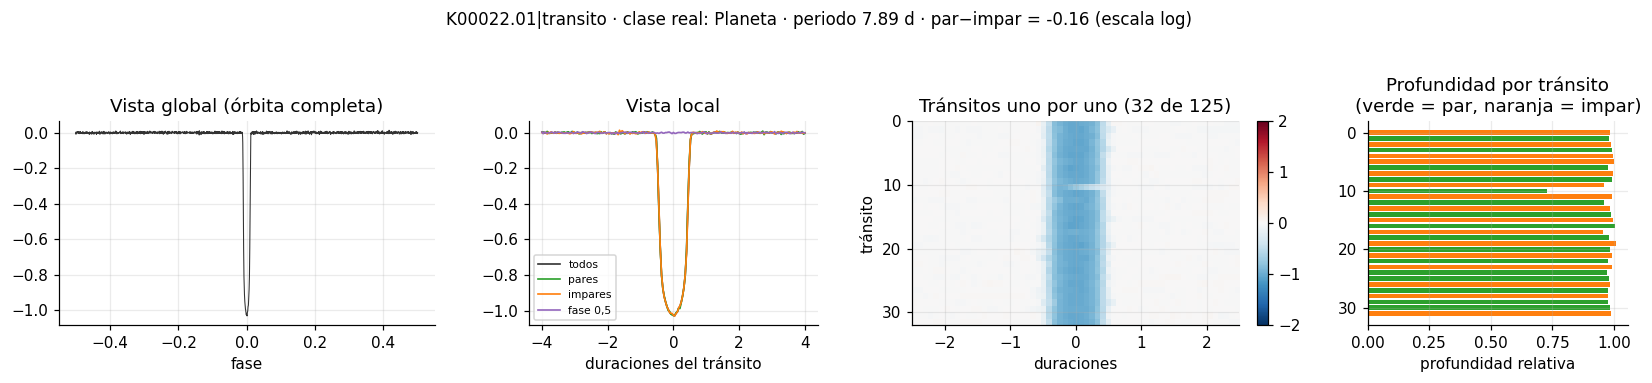

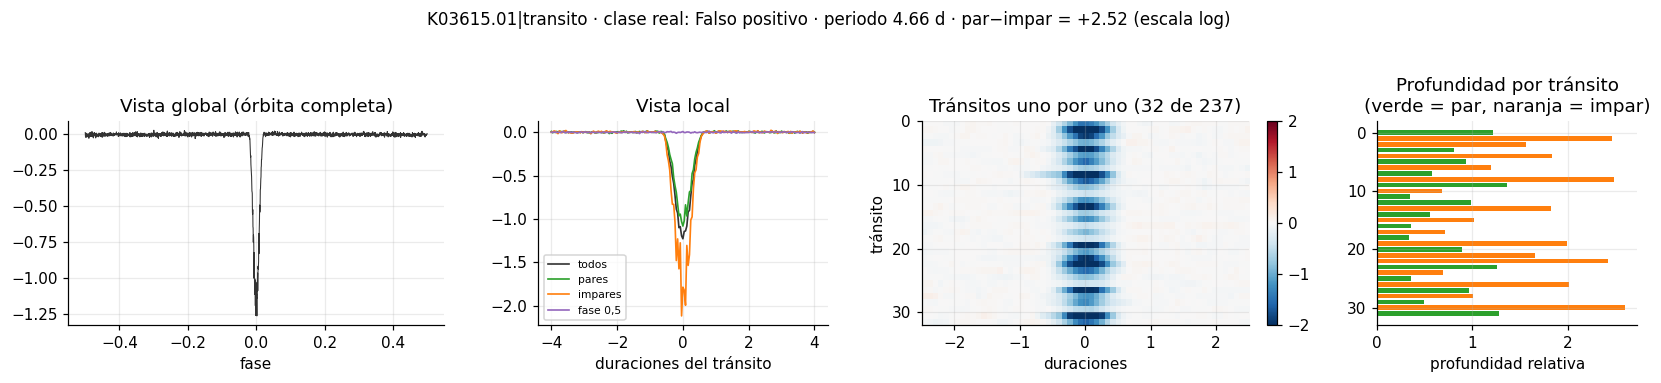

In [3]:
def ver_ejemplo(ident, pesos=None):
    i = pos[ident]; fig, ax = plt.subplots(1, 4, figsize=(15, 3.3), gridspec_kw={"width_ratios": [1.3, 1, 1.25, 0.9]})
    ax[0].plot(np.linspace(-0.5, 0.5, 2001), D["vista_global"][i, :, 0], lw=0.7, color="#333"); ax[0].set_title("Vista global (órbita completa)"); ax[0].set_xlabel("fase")
    x = np.linspace(-4, 4, 201)
    for ch, (nom, col) in enumerate((("todos", "#333"), ("pares", "#2ca02c"), ("impares", "#ff7f0e"), ("fase 0,5", "#9467bd"))):
        ax[1].plot(x, D["vista_local"][i, :, ch], lw=1.1, color=col, label=nom)
    ax[1].set_title("Vista local"); ax[1].set_xlabel("duraciones del tránsito"); ax[1].legend(fontsize=7)
    n = int(D["mascara_transitos"][i].sum())
    im = ax[2].imshow(D["transitos"][i, :max(n, 1)], aspect="auto", cmap="RdBu_r", vmin=-2, vmax=2, extent=[-2.5, 2.5, max(n, 1), 0])
    ax[2].set_title(f"Tránsitos uno por uno ({n} de {int(D['n_transitos_validos'][i])})"); ax[2].set_xlabel("duraciones"); ax[2].set_ylabel("tránsito")
    plt.colorbar(im, ax=ax[2], fraction=0.045)
    prof = -D["transitos"][i, :n, 27:34].mean(1); par = D["paridad_transitos"][i, :n]
    ax[3].barh(np.arange(n), prof, color=np.where(par == 0, "#2ca02c", "#ff7f0e")); ax[3].invert_yaxis()
    ax[3].set_title("Profundidad por tránsito\n(verde = par, naranja = impar)"); ax[3].set_xlabel("profundidad relativa")
    fila = tabla.iloc[i]
    fig.suptitle(f"{ident} · clase real: {CLASES[fila.clase]} · periodo {fila.periodo_d:.2f} d · par−impar = {D['consistencia'][i, 1]:+.2f} (escala log)", y=1.04, fontsize=11)
    plt.tight_layout(); plt.show()

ver_ejemplo("K00022.01|transito"); ver_ejemplo("K03615.01|transito")

## 2 · El listón

Antes de entrenar redes se midió qué logra un modelo **tabular** (gradient boosting) sin columnas con fuga, y se volvió a medir la **demo** sobre esta misma base y con las mismas particiones.

- **S3-B:** periodo, duración, profundidad, SNR, número de tránsitos y magnitud.
- **S3-C:** S3-B más el desplazamiento de centroide.
- `koi_score` es la decisión del Robovetter de NASA: **nunca es una entrada**, solo un comparador externo.

Todas las barras son **AUC planeta vs falso positivo** (0,5 = azar, 1 = perfecto) con su **intervalo de confianza del 95 %**, calculado remuestreando estrellas.

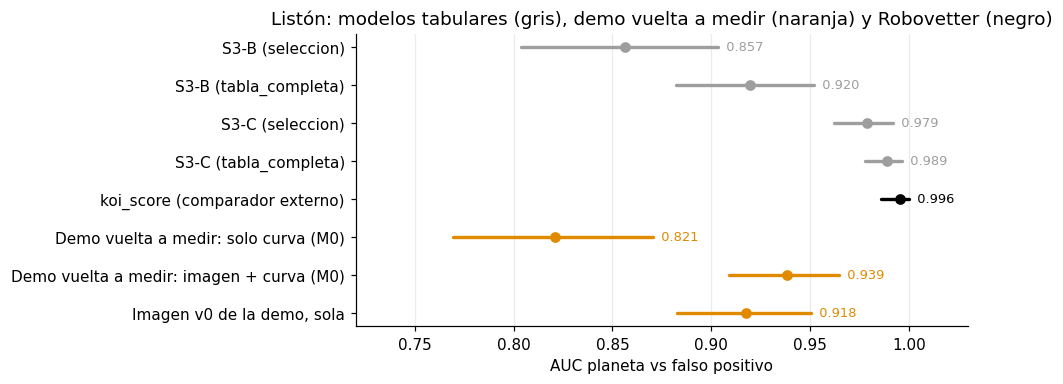

,modelo,auc,ic_inf,ic_sup,n
0,S3-B (seleccion),0.8565,0.8039,0.9037,245
1,S3-B (tabla_completa),0.9199,0.8823,0.9518,245
2,S3-C (seleccion),0.9788,0.9623,0.9921,245
3,S3-C (tabla_completa),0.9889,0.9781,0.9964,245
4,"koi_score (comparador externo, contiene la dec...",0.9956,0.9861,1.0000,245
5,Demo vuelta a medir: solo curva (M0),0.8212,0.7694,0.8707,222
6,Demo vuelta a medir: imagen + curva (M0),0.9385,0.9089,0.9646,222
7,"Imagen v0 de la demo, sola",0.9178,0.8826,0.9503,222


In [4]:
lb = pd.read_csv(T / "lineas_base.csv")
fig, ax = plt.subplots(figsize=(9, 3.6))
col = [COL["demo"] if "Demo" in m or "demo" in m else ("#000" if "koi_score" in m else COL["base"]) for m in lb.modelo]
bosque(ax, [m.replace(", contiene la decisión del Robovetter", "") for m in lb.modelo], lb.auc, lb.ic_inf, lb.ic_sup, col)
ax.set_xlabel("AUC planeta vs falso positivo"); ax.set_xlim(0.72, 1.03); ax.set_title("Listón: modelos tabulares (gris), demo vuelta a medir (naranja) y Robovetter (negro)")
plt.tight_layout(); plt.show(); display(lb)

**Lectura.** Con el centroide, un modelo tabular ya llega a **0,98–0,99**. Hay dos advertencias que el informe declara:

1. En periodo corto la revisión de Kepler ya funciona bien; no hay mucho margen por encima de ese listón.
2. Parte de las etiquetas de falso positivo se asignaron *usando* el centroide, así que S3-C mide en parte la regla que puso la etiqueta (circularidad parcial).

## 3 · P1 — ¿Qué arquitectura lee mejor la señal de tránsito?

Diseño controlado: las tres variantes de la rama 2 usan **el mismo codificador por tránsito** (una CNN 1D con pesos compartidos) y **las mismas ventanas**. Solo cambia **cómo se combinan los tránsitos**:

| Variante | Cómo combina | Supuesto que mete (sesgo inductivo) |
|---|---|---|
| Promedio | Media de los tránsitos | Todos pesan igual; el orden no importa. Equivale a plegar la curva |
| GRU | Los lee en orden cronológico | El orden importa |
| Atención | Suma ponderada con pesos aprendidos | Algunos tránsitos importan más; el orden no importa |

La CNN tipo AstroNet sobre la vista plegada (rama 1) es la línea base profunda. Cada modelo se entrenó con 3 semillas × 5 particiones.

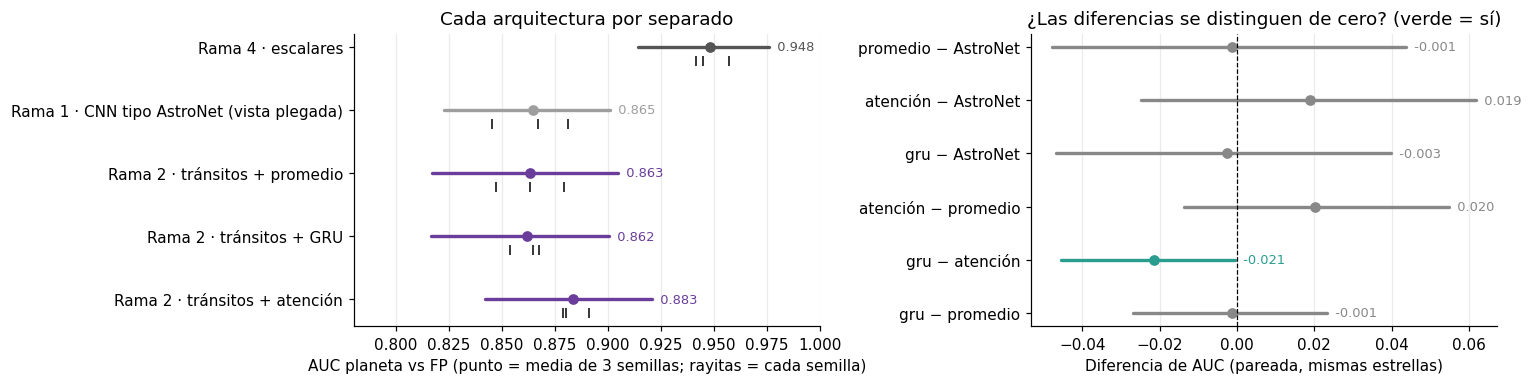

,estimacion,ic_inf,ic_sup,parametros,desviacion_semillas
modelo,,,,,
Rama 4 · escalares,0.9479,0.9142,0.9758,1059.0,0.0068
Rama 1 · CNN tipo AstroNet (vista plegada),0.8645,0.8225,0.9007,57747.0,0.0147
Rama 2 · tránsitos + promedio,0.8632,0.8170,0.9045,5027.0,0.0130
Rama 2 · tránsitos + GRU,0.8619,0.8165,0.9003,18723.0,0.0058
Rama 2 · tránsitos + atención,0.8834,0.8419,0.9208,13604.0,0.0055


In [5]:
p1 = pd.read_csv(T / "p1_arquitecturas.csv")
NOM = {"m4_escalares": "Rama 4 · escalares", "m1_astronet": "Rama 1 · CNN tipo AstroNet (vista plegada)",
       "m2_promedio": "Rama 2 · tránsitos + promedio", "m2_gru": "Rama 2 · tránsitos + GRU", "m2_atencion": "Rama 2 · tránsitos + atención"}
m = p1[(p1.tipo == "modelo") & (p1.metrica == "auc_planeta_fp")].set_index("modelo").loc[list(NOM)]
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6), gridspec_kw={"width_ratios": [1, 1]})
bosque(ax[0], [NOM[k] for k in m.index], m.estimacion, m.ic_inf, m.ic_sup, ["#555", COL["base"], COL["curso"], COL["curso"], COL["curso"]])
for k, a in zip(m.index, np.arange(len(m))[::-1]):
    s = [leer(R / k / "metricas.json")["por_semilla"][str(i)]["auc_planeta_fp"] for i in range(3)]
    ax[0].plot(s, [a - 0.22] * 3, "|", color="k", ms=7)
ax[0].set_xlabel("AUC planeta vs FP (punto = media de 3 semillas; rayitas = cada semilla)"); ax[0].set_xlim(0.78, 1.0); ax[0].set_title("Cada arquitectura por separado")
d = p1[(p1.tipo == "diferencia") & (p1.metrica == "auc_planeta_fp")]
etiq = [x.replace("m2_", "").replace("m1_astronet", "AstroNet").replace("atencion", "atención") for x in d.modelo]
bosque(ax[1], etiq, d.estimacion, d.ic_inf, d.ic_sup, ["#2a9d8f" if v else "#888" for v in d.distinguible], ref=0)
ax[1].set_xlabel("Diferencia de AUC (pareada, mismas estrellas)"); ax[1].set_title("¿Las diferencias se distinguen de cero? (verde = sí)")
plt.tight_layout(); plt.show()
display(m[["estimacion", "ic_inf", "ic_sup", "parametros", "desviacion_semillas"]].rename(index=NOM).round(4))

**Lectura.**

- La **atención** tiene el AUC más alto de las ramas temporales, pero **su ventaja sobre el promedio y sobre AstroNet no se distingue de cero**: los intervalos de las diferencias incluyen el 0.
- La única diferencia distinguible es **atención > GRU**, y por poco.
- Era el resultado esperable en periodo corto: con decenas o cientos de tránsitos por estrella, promediar ya recoge casi toda la información. La hipótesis de que la atención ayuda con *pocos* tránsitos (zona habitable) **no se puede evaluar con estos datos**.

### ¿Importa el orden de los tránsitos? (prueba de permutación)

Se barajó el orden de los tránsitos de cada ejemplo de prueba, 10 veces, y se midió cuánto cambia la probabilidad.

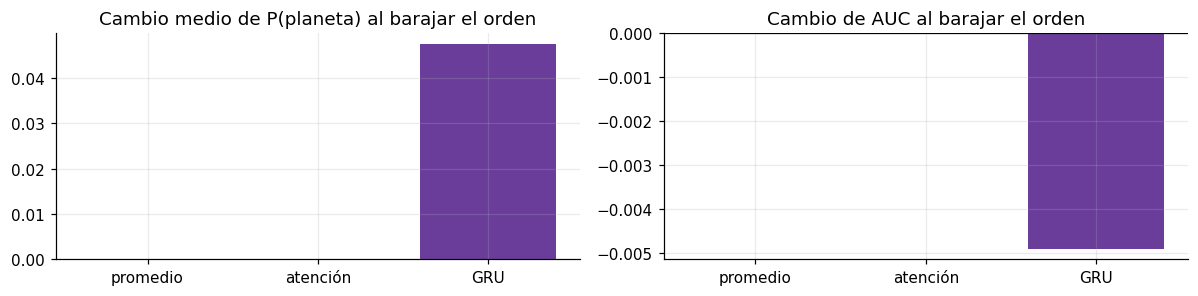

,modelo,cambio_medio_abs_de_q,cambio_de_auc
0,m2_promedio,0.00000,-0.0000
1,m2_atencion,0.00000,-0.0000
2,m2_gru,0.04757,-0.0049


In [6]:
perm = pd.read_csv(T / "p1_permutacion_resumen.csv")
fig, ax = plt.subplots(1, 2, figsize=(11, 2.8))
n = [NOM[k].replace("Rama 2 · tránsitos + ", "") for k in perm.modelo]
ax[0].bar(n, perm.cambio_medio_abs_de_q, color=[COL["curso"]] * 3); ax[0].set_title("Cambio medio de P(planeta) al barajar el orden")
ax[1].bar(n, perm.cambio_de_auc, color=[COL["curso"]] * 3); ax[1].set_title("Cambio de AUC al barajar el orden"); ax[1].axhline(0, color="k", lw=0.8)
plt.tight_layout(); plt.show(); display(perm)

**Lectura.** Promedio y atención **no cambian nada** (cambio exactamente 0): por construcción ignoran el orden, y la prueba confirma que la implementación lo cumple. La GRU **sí usa el orden** (cambia la probabilidad en unos 0,05 en promedio), pero esa información extra no le dio ventaja.

### ¿Cómo entrenaron? (curvas de pérdida)

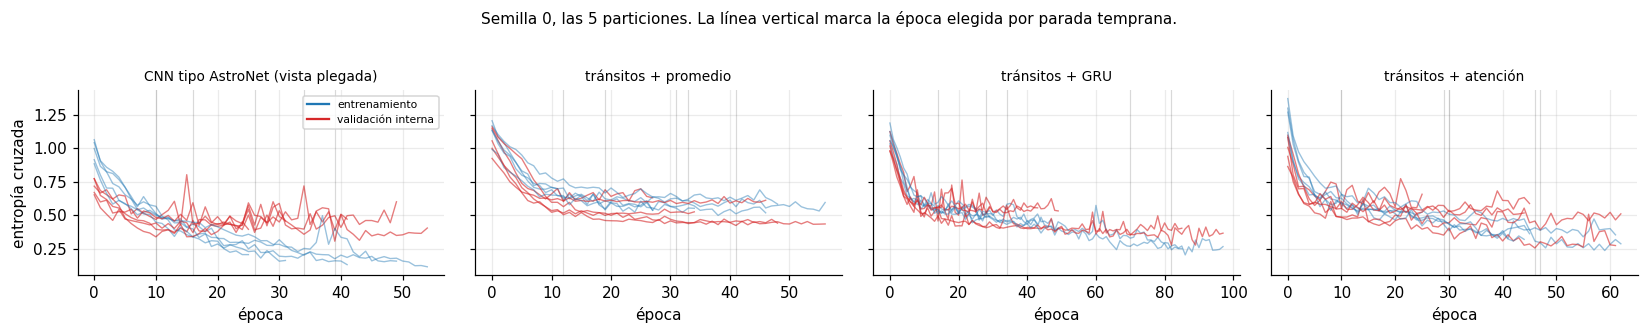

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(15, 2.9), sharey=True)
for a, k in zip(ax, ["m1_astronet", "m2_promedio", "m2_gru", "m2_atencion"]):
    for h in leer(R / k / "historial_semilla0.json"):
        a.plot(h["perdida_entrenamiento"], color="#1f77b4", alpha=0.45, lw=0.9); a.plot(h["perdida_validacion"], color="#d62728", alpha=0.6, lw=0.9)
        a.axvline(h["epoca_elegida"] - 1, color="k", alpha=0.15, lw=0.8)
    a.set_title(NOM[k].split("· ")[1], fontsize=9); a.set_xlabel("época")
ax[0].set_ylabel("entropía cruzada"); ax[0].plot([], [], color="#1f77b4", label="entrenamiento"); ax[0].plot([], [], color="#d62728", label="validación interna"); ax[0].legend(fontsize=7)
plt.suptitle("Semilla 0, las 5 particiones. La línea vertical marca la época elegida por parada temprana.", y=1.03, fontsize=10); plt.tight_layout(); plt.show()

## 4 · ¿A qué tránsitos presta atención el modelo?

Doce ejemplos elegidos **al azar con semilla fija** (4 por clase), no por haber acertado. Arriba, los tránsitos uno por uno; abajo, el peso que la atención le dio a cada uno.

> Los pesos de atención **describen** qué combinó el modelo; no son una explicación causal de su decisión (Jain y Wallace, 2019).

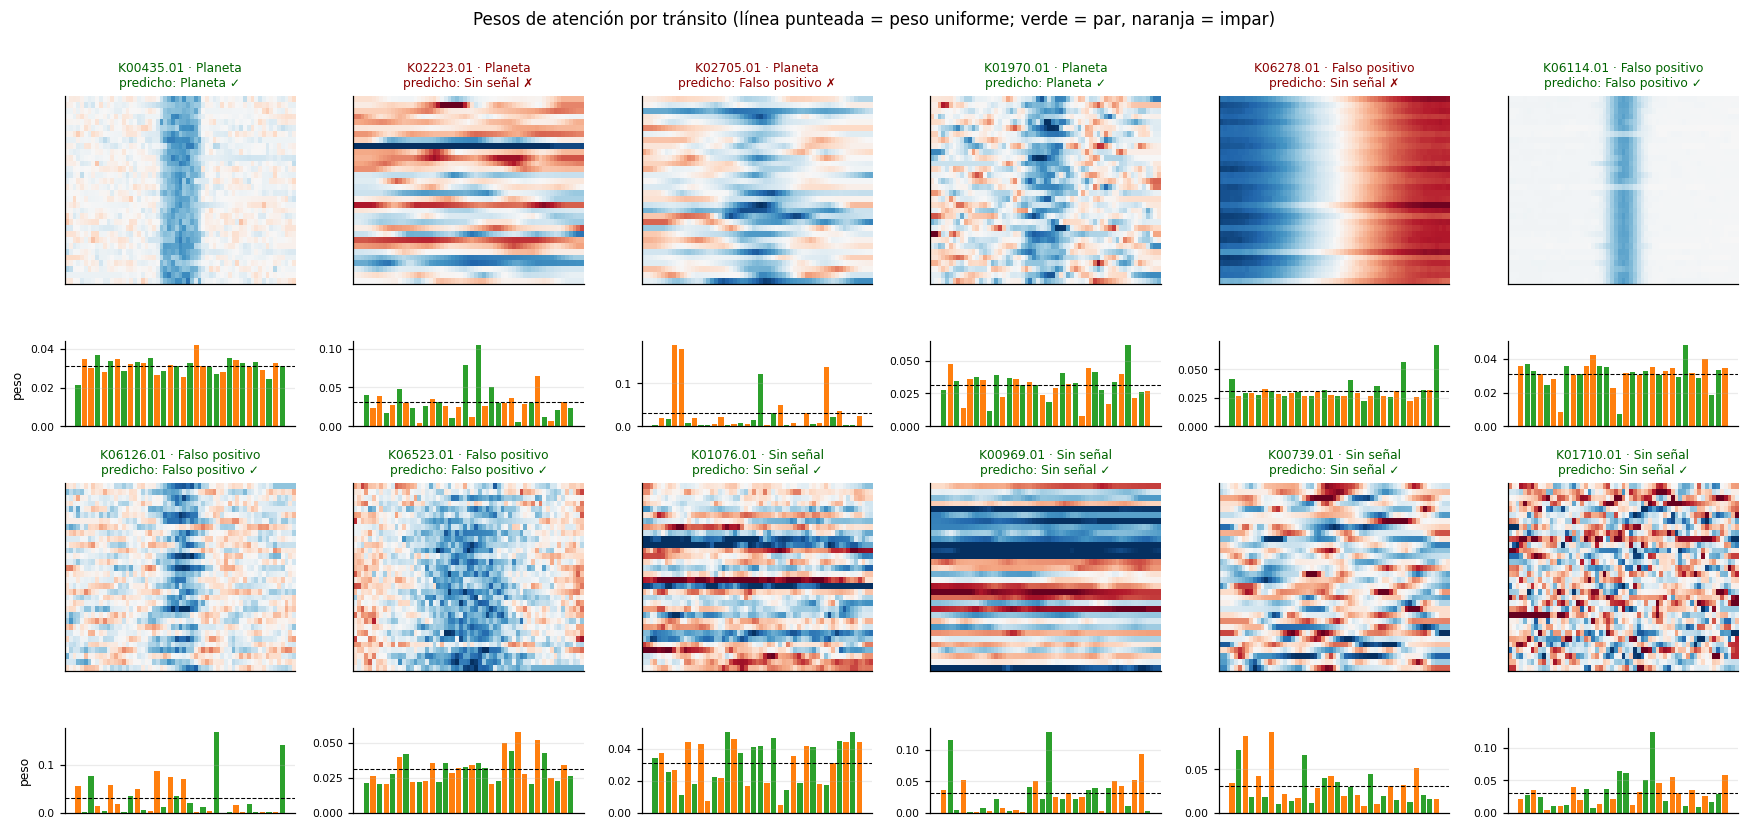

In [8]:
W = np.load(R / "m2_atencion" / "pesos_atencion_casos.npz", allow_pickle=False)
fig, ax = plt.subplots(4, 6, figsize=(16, 7.5), gridspec_kw={"height_ratios": [2.2, 1, 2.2, 1]})
for j in range(12):
    f, c = (j // 6) * 2, j % 6; n = int(W["mascara_transitos"][j].sum())
    ax[f, c].imshow(W["transitos"][j, :n], aspect="auto", cmap="RdBu_r", vmin=-2, vmax=2); ax[f, c].set_xticks([]); ax[f, c].set_yticks([])
    ok = W["p"][j].argmax() == W["clase"][j]
    ax[f, c].set_title(f"{W['id_ejemplo'][j].split('|')[0]} · {CLASES[W['clase'][j]]}\npredicho: {CLASES[W['p'][j].argmax()]} {'✓' if ok else '✗'}", fontsize=8, color="darkgreen" if ok else "darkred")
    ax[f + 1, c].bar(np.arange(n), W["pesos"][j, :n], color=np.where(W["paridad_transitos"][j, :n] == 0, "#2ca02c", "#ff7f0e"))
    ax[f + 1, c].axhline(1 / max(n, 1), color="k", ls="--", lw=0.7); ax[f + 1, c].set_xticks([]); ax[f + 1, c].tick_params(labelsize=7)
ax[1, 0].set_ylabel("peso", fontsize=8); ax[3, 0].set_ylabel("peso", fontsize=8)
plt.suptitle("Pesos de atención por tránsito (línea punteada = peso uniforme; verde = par, naranja = impar)", y=1.0, fontsize=11); plt.tight_layout(); plt.show()

## 5 · P2 — ¿Cuánto mejora la decisión al fusionar las cuatro ramas?

Cada rama resume su entrada en un vector (32, 32, 32 y 16 números). La **fusión** concatena los cuatro, agrega 4 banderas de disponibilidad y decide con una capa densa pequeña. Los codificadores están **congelados**, uno por partición, de modo que ninguno vio las estrellas de prueba.

La **ablación** reentrena la cabeza quitando una rama a la vez, o dejando una sola.

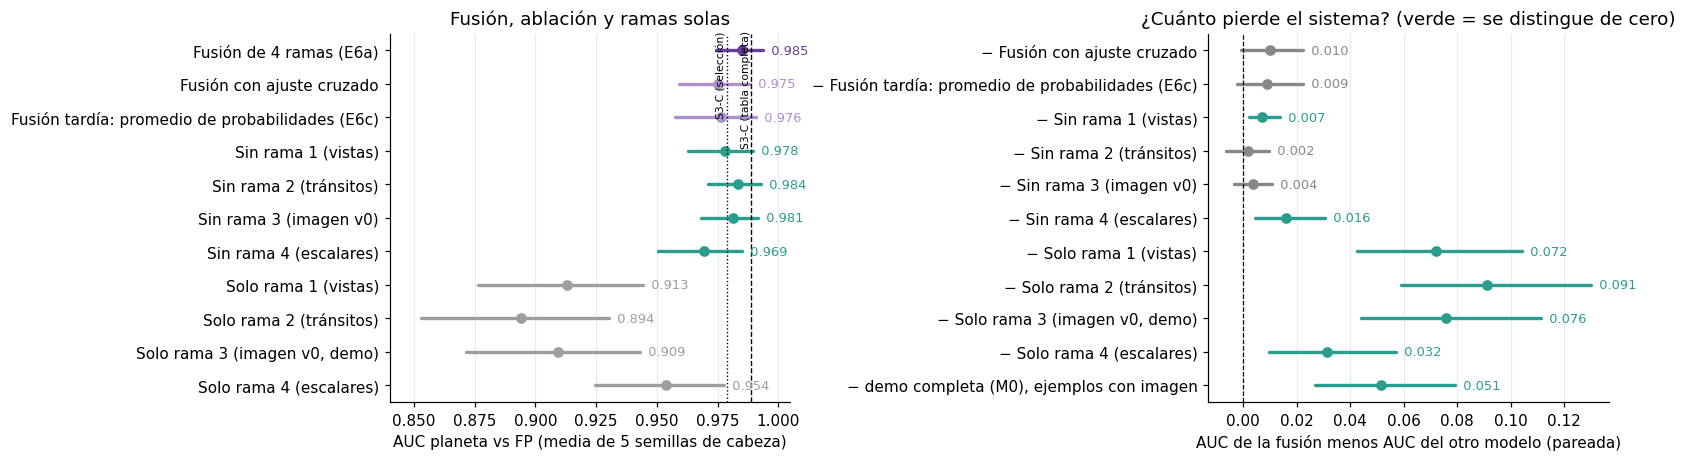

In [9]:
p2 = pd.read_csv(T / "p2_fusion.csv")
m = p2[(p2.tipo == "modelo") & (p2.metrica == "auc_planeta_fp")]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.3))
col = [COL["curso"] if c.startswith("e6a_cuatro") else ("#b08fd0" if c.startswith("e6") else ("#2a9d8f" if "sin" in c else COL["base"])) for c in m.clave]
bosque(ax[0], list(m.modelo), m.estimacion, m.ic_inf, m.ic_sup, col)
lb = pd.read_csv(T / "lineas_base.csv").set_index("modelo")
for nom, ls in (("S3-C (seleccion)", ":"), ("S3-C (tabla_completa)", "--")):
    ax[0].axvline(lb.loc[nom, "auc"], color="k", ls=ls, lw=0.9); ax[0].text(lb.loc[nom, "auc"], len(m) - 0.4, nom.replace("seleccion", "selección").replace("tabla_completa", "tabla completa"), rotation=90, fontsize=7, va="top", ha="right")
ax[0].set_xlim(0.84, 1.005); ax[0].set_xlabel("AUC planeta vs FP (media de 5 semillas de cabeza)"); ax[0].set_title("Fusión, ablación y ramas solas")
d = p2[(p2.tipo == "diferencia") & (p2.metrica == "auc_planeta_fp")]
bosque(ax[1], [x.replace("Fusión (E6a) − ", "− ") for x in d.modelo], d.estimacion, d.ic_inf, d.ic_sup, ["#2a9d8f" if v else "#888" for v in d.distinguible], ref=0)
ax[1].set_xlabel("AUC de la fusión menos AUC del otro modelo (pareada)"); ax[1].set_title("¿Cuánto pierde el sistema? (verde = se distingue de cero)")
plt.tight_layout(); plt.show()

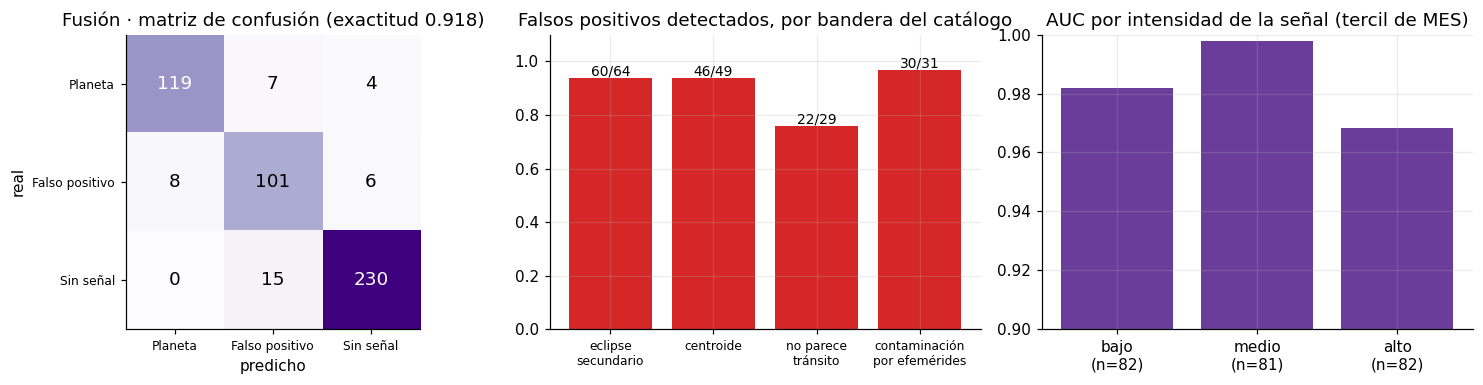

Diagnóstico del apilado: NLL de la cabeza en entrenamiento 0.0497 · en validación interna 0.1786 · razón 3.59 → alerta: True


In [10]:
fus = leer(R / "fusion" / "e6a_cuatro_ramas" / "metricas.json")
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
cm = np.array(fus["semilla_0"]["matriz_confusion"]); ax[0].imshow(cm, cmap="Purples"); ax[0].grid(False)
for (r, c), v in np.ndenumerate(cm): ax[0].text(c, r, v, ha="center", va="center", color="white" if v > cm.max() / 2 else "black", fontsize=12)
ax[0].set_xticks(range(3)); ax[0].set_xticklabels(CLASES, fontsize=8); ax[0].set_yticks(range(3)); ax[0].set_yticklabels(CLASES, fontsize=8)
ax[0].set_xlabel("predicho"); ax[0].set_ylabel("real"); ax[0].set_title(f"Fusión · matriz de confusión (exactitud {fus['semilla_0']['global']['exactitud']['estimacion']:.3f})")
b = fus["semilla_0"]["acierto_fp_por_bandera"]; nom = {"fp_ss": "eclipse\nsecundario", "fp_co": "centroide", "fp_nt": "no parece\ntránsito", "fp_ec": "contaminación\npor efemérides"}
ax[1].bar([nom[k] for k in b], [v["aciertos"] / v["n"] for v in b.values()], color=COL["fp"])
for i, v in enumerate(b.values()): ax[1].text(i, v["aciertos"] / v["n"] + 0.01, f"{v['aciertos']}/{v['n']}", ha="center", fontsize=9)
ax[1].set_ylim(0, 1.1); ax[1].set_title("Falsos positivos detectados, por bandera del catálogo"); ax[1].tick_params(axis="x", labelsize=8)
t = fus["semilla_0"]["auc_por_tercil_mes"]
ax[2].bar([f"{k}\n(n={v['n']})" for k, v in t.items()], [v["estimacion"] for v in t.values()], color=COL["curso"]); ax[2].set_ylim(0.9, 1.0)
ax[2].set_title("AUC por intensidad de la señal (tercil de MES)")
plt.tight_layout(); plt.show()
ap = fus["apilado"]; print(f"Diagnóstico del apilado: NLL de la cabeza en entrenamiento {ap['nll_entrenamiento']} · en validación interna {ap['nll_validacion']} · razón {ap['razon']} → alerta: {ap['alerta']}")

**Lectura.**

- La **fusión de 4 ramas supera a cualquier rama sola** y a la demo vuelta a medir, con diferencias que se distinguen de cero.
- Al quitar ramas: perder los **escalares** o las **vistas** baja el AUC de forma distinguible. Perder la rama de **tránsitos** o la de **imagen** no se distingue de cero: en este régimen lo que aportan ya lo cubren las otras.
- Frente al listón tabular **S3-C**, la fusión queda **en el mismo rango** (los intervalos se solapan). No se puede afirmar que lo supere.
- **Sin escalares** (solo las tres ramas que aprenden de curvas e imagen) el sistema llega a ~0,97.
- **Alerta de apilado:** la cabeza ve en entrenamiento vectores de ejemplos que los codificadores ya conocían, y por eso queda demasiado confiada (su pérdida en validación es más de 2 veces la de entrenamiento). El remedio previsto —entrenar la cabeza solo con vectores que los codificadores no vieron— elimina la alerta y da un AUC algo menor, no distinguible. La sección siguiente mide y corrige esa sobreconfianza.

## 6 · P3 — ¿Se puede confiar en las probabilidades?

Un modelo puede acertar mucho y aun así mentir sobre su confianza. El **diagrama de confiabilidad** agrupa las predicciones por la confianza declarada y mide cuántas acertó. Si está calibrado, los puntos caen sobre la diagonal.

**Temperature scaling:** un solo número (la temperatura) suaviza o afila las probabilidades. Se ajusta en la **validación interna** de cada partición, nunca en la prueba.

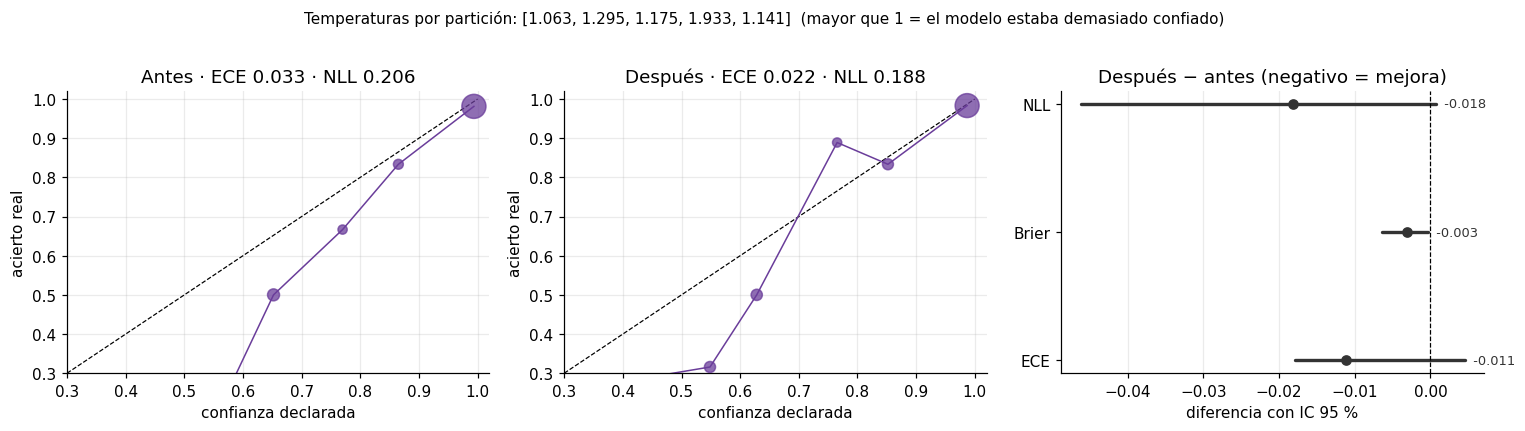

In [11]:
cal = leer(R / "calibracion" / "metricas.json"); PC = np.load(R / "calibracion" / "pred_calibrada.npz", allow_pickle=False)
def confiabilidad(ax, p, yy, titulo, n=10):
    conf, ok = p.max(1), (p.argmax(1) == yy).astype(float); b = np.clip((conf * n).astype(int), 0, n - 1)
    xs = [conf[b == i].mean() for i in range(n) if (b == i).sum() >= 5]; ys = [ok[b == i].mean() for i in range(n) if (b == i).sum() >= 5]; ns = [(b == i).sum() for i in range(n) if (b == i).sum() >= 5]
    ax.plot([0.3, 1], [0.3, 1], "k--", lw=0.8); ax.scatter(xs, ys, s=np.sqrt(ns) * 12, color=COL["curso"], alpha=0.75, zorder=3); ax.plot(xs, ys, color=COL["curso"], lw=1)
    ax.set_xlabel("confianza declarada"); ax.set_ylabel("acierto real"); ax.set_title(titulo); ax.set_xlim(0.3, 1.02); ax.set_ylim(0.3, 1.02)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
e8 = cal["E8_temperatura"]
confiabilidad(ax[0], PC["p_antes"], y, f"Antes · ECE {e8['antes']['ece_top']['estimacion']:.3f} · NLL {e8['antes']['nll']['estimacion']:.3f}")
confiabilidad(ax[1], PC["p_despues"], y, f"Después · ECE {e8['despues']['ece_top']['estimacion']:.3f} · NLL {e8['despues']['nll']['estimacion']:.3f}")
d = e8["diferencia_despues_menos_antes"]; k = ["nll", "brier", "ece_top"]
bosque(ax[2], ["NLL", "Brier", "ECE"], [d[i]["estimacion"] for i in k], [d[i]["ic_inf"] for i in k], [d[i]["ic_sup"] for i in k], ref=0)
ax[2].set_title("Después − antes (negativo = mejora)"); ax[2].set_xlabel("diferencia con IC 95 %")
plt.suptitle(f"Temperaturas por partición: {e8['temperaturas']}  (mayor que 1 = el modelo estaba demasiado confiado)", y=1.02, fontsize=10); plt.tight_layout(); plt.show()

**Lectura.** Todas las temperaturas son mayores que 1: el sistema estaba **sobreconfiado**, como anticipaba la alerta de apilado. Calibrar baja el ECE y el NLL, pero con ~490 ejemplos **la mejora no se distingue de cero** (los intervalos tocan el 0). El AUC no cambia, como debe ser.

### El prior explícito: ¿y si los planetas fueran escasos?

El modelo se entrenó con casi tantos planetas como falsos positivos. Si en la población real los planetas son raros, sus probabilidades quedan infladas. La corrección de Saerens et al. (2002) reajusta la probabilidad a una **tasa base declarada**. Para evaluarla, la prueba se pondera de modo que emule esa tasa.

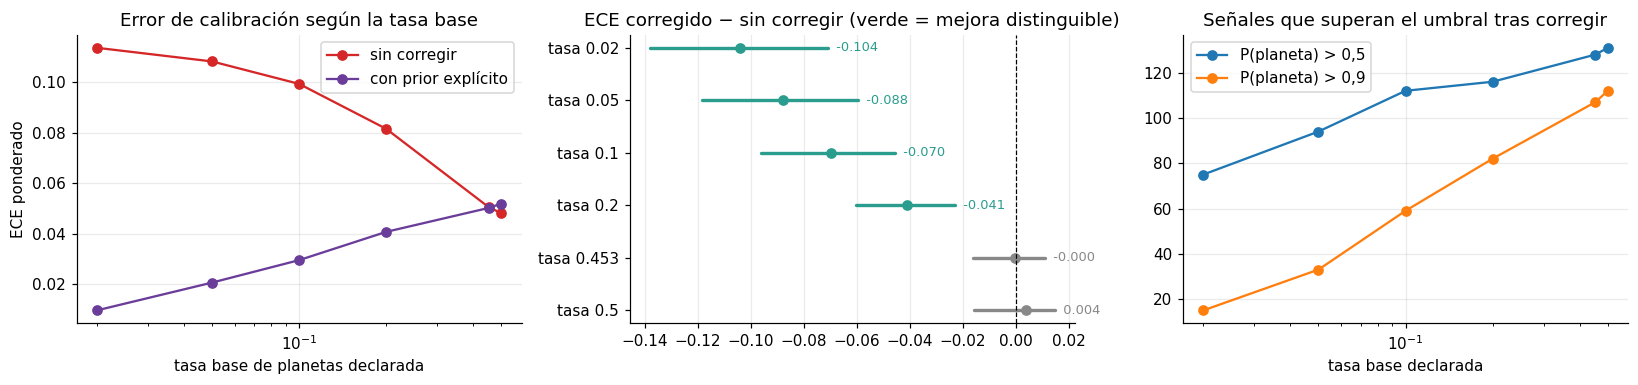

Tasa base medida en DR25 (periodo 1–30 d): {'valor': 0.453, 'confirmados': 2060, 'falsos_positivos': 2487} · tasa de entrenamiento: 0.5306


In [12]:
e9 = cal["E9_prior"]; r = pd.DataFrame(e9["por_tasa"]).T.sort_values("tasa")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(r.tasa, r.ece_ponderado_sin_corregir, "o-", color=COL["fp"], label="sin corregir"); ax[0].plot(r.tasa, r.ece_ponderado_corregido, "o-", color=COL["curso"], label="con prior explícito")
ax[0].set_xscale("log"); ax[0].set_xlabel("tasa base de planetas declarada"); ax[0].set_ylabel("ECE ponderado"); ax[0].set_title("Error de calibración según la tasa base"); ax[0].legend()
dd = pd.DataFrame(list(r.diferencia_corregido_menos_sin)); 
bosque(ax[1], [f"tasa {t:g}" for t in r.tasa], dd.estimacion, dd.ic_inf, dd.ic_sup, ["#2a9d8f" if h < 0 else "#888" for h in dd.ic_sup], ref=0)
ax[1].set_title("ECE corregido − sin corregir (verde = mejora distinguible)")
a5 = np.array([v[1] for v in r["candidatos_con_q_mayor_0.5"]]); a9 = np.array([v[1] for v in r["candidatos_con_q_mayor_0.9"]])
ax[2].plot(r.tasa, a5, "o-", label="P(planeta) > 0,5"); ax[2].plot(r.tasa, a9, "o-", label="P(planeta) > 0,9"); ax[2].set_xscale("log")
ax[2].set_xlabel("tasa base declarada"); ax[2].set_title("Señales que superan el umbral tras corregir"); ax[2].legend()
plt.tight_layout(); plt.show()
print("Tasa base medida en DR25 (periodo 1–30 d):", e9["tasa_dr25"], "· tasa de entrenamiento:", e9["tasa_entrenamiento_media"])

**Lectura.** Cuando la tasa declarada se parece a la de entrenamiento (~0,5) corregir no cambia nada. Cuando los planetas son escasos (tasa ≤ 0,2), **el prior explícito reduce el error de calibración de forma distinguible**, y muchas menos señales superan el umbral. El orden de los candidatos casi no cambia (τ de Kendall > 0,98): la corrección cambia *cuánto* creer, no *a quién* mirar primero.

> **Límite.** La corrección supone que solo cambia la tasa base, no el aspecto de las señales. Eso **no** se cumple entre periodo corto y zona habitable: aquí se demuestra el mecanismo, no su validez en ese régimen.

### Incertidumbre: ¿el modelo duda cuando se equivoca?

Dos formas de medir la duda de la cabeza de fusión: **MC Dropout** (repetir la predicción 50 veces con neuronas apagadas al azar) y un **ensamble** de 5 cabezas entrenadas con semillas distintas.

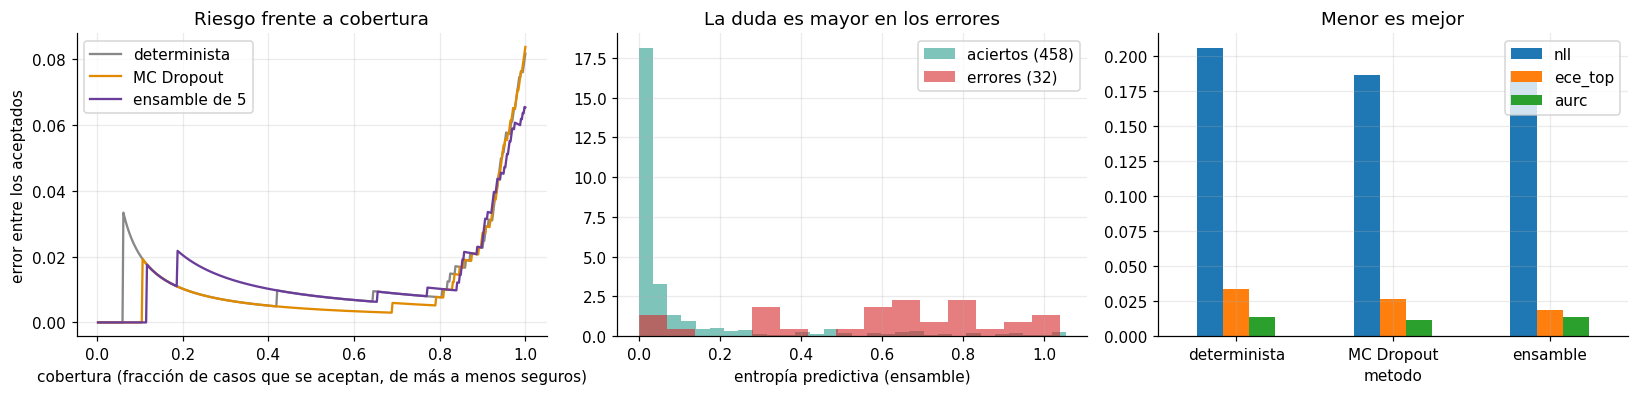

,nll,brier,ece_top,exactitud,aurc,auroc_deteccion_errores,entropia_media_aciertos,entropia_media_errores,nll_ic_inf,nll_ic_sup
metodo,,,,,,,,,,
determinista_semilla_0,0.2058,0.1034,0.0333,0.9184,0.0140,0.9246,0.0746,0.6270,0.1368,0.2882
mc_dropout,0.1860,0.1017,0.0264,0.9163,0.0113,0.9416,0.0988,0.6771,0.1314,0.2480
ensamble_5_semillas,0.1893,0.0970,0.0190,0.9347,0.0139,0.8886,0.1039,0.6044,0.1273,0.2620


NLL ensamble − MC Dropout: {'estimacion': 0.0033, 'ic_inf': -0.0192, 'ic_sup': 0.0344}


In [13]:
inc = leer(R / "incertidumbre" / "metricas.json"); PI = np.load(R / "incertidumbre" / "predicciones.npz", allow_pickle=False)
H = lambda p: -(p * np.log(np.clip(p, 1e-12, 1))).sum(1)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.7))
for nom, clave, col in (("determinista", "p_determinista", "#888"), ("MC Dropout", "p_mc_dropout", "#e08a00"), ("ensamble de 5", "p_ensamble", COL["curso"])):
    p = PI[clave]; ok = (p.argmax(1) == y).astype(float); o = np.argsort(H(p)); cob = np.arange(1, len(o) + 1) / len(o)
    ax[0].plot(cob, np.cumsum(1 - ok[o]) / np.arange(1, len(o) + 1), color=col, label=nom)
ax[0].set_xlabel("cobertura (fracción de casos que se aceptan, de más a menos seguros)"); ax[0].set_ylabel("error entre los aceptados"); ax[0].set_title("Riesgo frente a cobertura"); ax[0].legend()
p = PI["p_ensamble"]; ok = p.argmax(1) == y
ax[1].hist(H(p)[ok], bins=30, alpha=0.6, color="#2a9d8f", density=True, label=f"aciertos ({ok.sum()})"); ax[1].hist(H(p)[~ok], bins=15, alpha=0.6, color=COL["fp"], density=True, label=f"errores ({(~ok).sum()})")
ax[1].set_xlabel("entropía predictiva (ensamble)"); ax[1].set_title("La duda es mayor en los errores"); ax[1].legend()
t = pd.read_csv(T / "p3_incertidumbre.csv").set_index("metodo")
t[["nll", "ece_top", "aurc"]].plot.bar(ax=ax[2], rot=0); ax[2].set_xticklabels(["determinista", "MC Dropout", "ensamble"]); ax[2].set_title("Menor es mejor")
plt.tight_layout(); plt.show(); display(t.round(4)); print("NLL ensamble − MC Dropout:", inc["diferencia_nll_ensamble_menos_mc"])

**Lectura.** La incertidumbre **sí avisa**: los errores tienen mucha más entropía que los aciertos, y si se rechaza una pequeña fracción de los casos más dudosos el error cae con fuerza. Entre MC Dropout y el ensamble **no hay una diferencia distinguible** en NLL. La incertidumbre solo cubre la cabeza de fusión, porque los codificadores están congelados.

## 7 · Explorador interactivo

Elige cualquier señal y mira **sus datos**, **qué opinó cada rama** y **qué decidió el sistema**. El deslizador cambia la tasa base declarada y muestra cómo se mueve la probabilidad de planeta.

*(Requiere ejecutar el notebook con `ipywidgets`. Si no está instalado, abajo queda una vista fija de ejemplo.)*

In [14]:
RAMAS_P = {"Rama 1 · vistas": pred("m1_astronet"), "Rama 2 · tránsitos (atención)": pred("m2_atencion"), "Rama 3 · imagen v0 (demo)": pred("imagen_v0"),
           "Rama 4 · escalares": pred("m4_escalares"), "FUSIÓN (calibrada)": np.asarray(PC["p_despues"], float)}
P_ENS, IM = PI["p_ensamble"], PI["im_ensamble"]
ERR = P_ENS.argmax(1) != y

def corregir(q, tasa, tasa_ent=0.53):
    r = (tasa / (1 - tasa)) / (tasa_ent / (1 - tasa_ent)); return q * r / (q * r + 1 - q)

def explorar(ident, tasa=0.5):
    i = pos[ident]; ver_ejemplo(ident)
    fig, ax = plt.subplots(1, 2, figsize=(13, 2.9), gridspec_kw={"width_ratios": [2.2, 1]})
    nombres = list(RAMAS_P); M = np.array([RAMAS_P[k][i] for k in nombres]); izq = np.zeros(len(nombres))
    for c, col in enumerate((COL["planeta"], COL["fp"], COL["nada"])):
        ax[0].barh(nombres, np.nan_to_num(M[:, c]), left=izq, color=col, label=CLASES[c]); izq += np.nan_to_num(M[:, c])
    for j, k in enumerate(nombres):
        if np.isnan(M[j]).any(): ax[0].text(0.5, j, "sin dato para este ejemplo", ha="center", va="center", fontsize=8)
    ax[0].invert_yaxis(); ax[0].set_xlim(0, 1); ax[0].legend(ncol=3, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, 1.0)); ax[0].grid(False)
    pf = RAMAS_P["FUSIÓN (calibrada)"][i]; q = pf[0] / (pf[0] + pf[1] + 1e-12); qc = corregir(q, tasa)
    ax[1].bar(["sin corregir", f"tasa base {tasa:g}"], [q, qc], color=[COL["base"], COL["curso"]]); ax[1].set_ylim(0, 1.05)
    for j, v in enumerate((q, qc)): ax[1].text(j, v + 0.02, f"{v:.3f}", ha="center")
    ax[1].set_title("P(planeta | hay señal)")
    plt.tight_layout(); plt.show()
    f = tabla.iloc[i]; e = D["escalares"][i]
    print(f"Real: {CLASES[f.clase]} · predicho por la fusión: {CLASES[int(P_ENS[i].argmax())]} {'✗ ERROR' if ERR[i] else '✓'} · entropía {H(P_ENS[i:i+1])[0]:.3f} · desacuerdo entre cabezas {IM[i]:.4f}")
    print(f"Periodo {f.periodo_d:.3f} d · duración {f.duracion_h:.2f} h · profundidad medida {e[2]:.0f} ppm · SNR medido {e[3]:.1f} · MES {f.mes:.1f} · banderas del catálogo (solo informativas): nt={f.fp_nt} ss={f.fp_ss} co={f.fp_co} ec={f.fp_ec}")

try:
    import ipywidgets as w
    grupos = {"Errores de la fusión": ids[ERR], "Planetas": ids[y == 0], "Falsos positivos": ids[y == 1], "Sin señal": ids[y == 2], "Más dudosos (entropía alta)": ids[np.argsort(-H(P_ENS))[:40]]}
    sel_g = w.Dropdown(options=list(grupos), description="Grupo:"); sel_i = w.Dropdown(options=sorted(grupos[sel_g.value]), description="Señal:")
    desl = w.SelectionSlider(options=[0.02, 0.05, 0.1, 0.2, 0.453, 0.5], value=0.5, description="Tasa base:")
    def _g(c): sel_i.options = sorted(grupos[sel_g.value])
    sel_g.observe(_g, names="value")
    display(w.HBox([sel_g, sel_i, desl]), w.interactive_output(explorar, {"ident": sel_i, "tasa": desl}))
except ImportError:
    print("ipywidgets no está instalado: se muestra un caso fijo."); explorar("K03615.01|transito", 0.05)

Output()

### Vista fija de dos casos (por si el explorador no está activo)

`K00022.01` es el error típico de la demo: un planeta gigante que su imagen saturaba y clasificaba como falso positivo. El segundo es un error actual del sistema, elegido al azar con semilla fija.

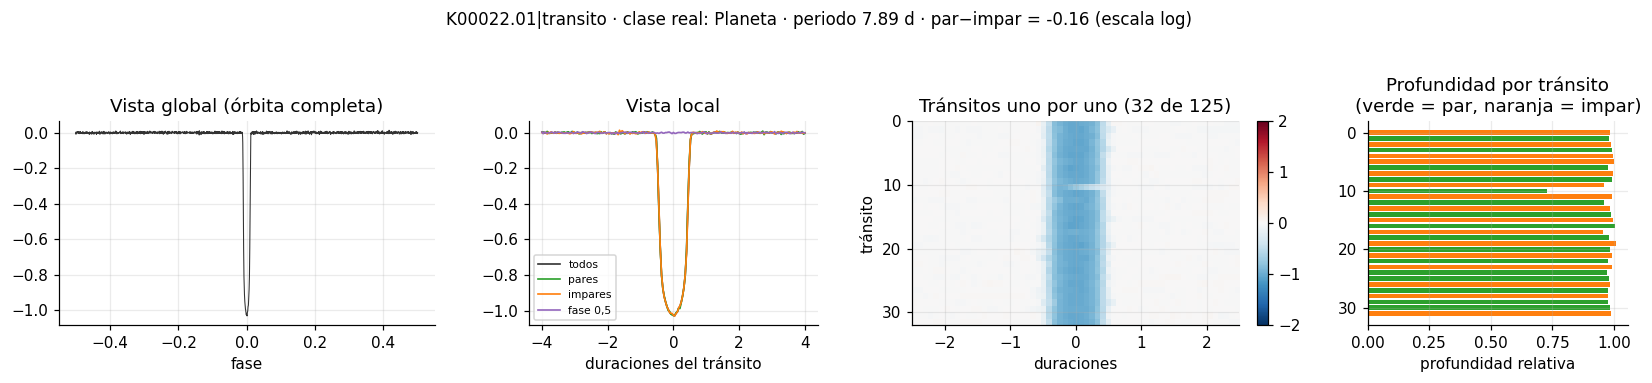

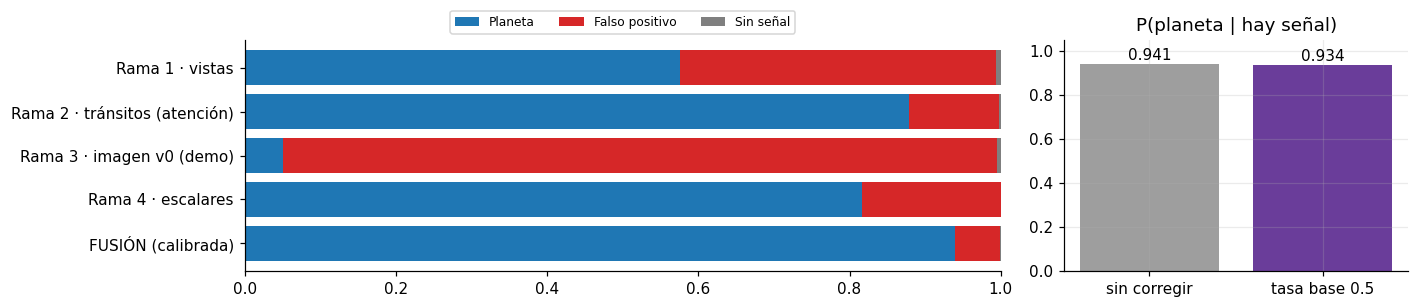

Real: Planeta · predicho por la fusión: Planeta ✓ · entropía 0.196 · desacuerdo entre cabezas 0.0105
Periodo 7.891 d · duración 4.29 h · profundidad medida 10125 ppm · SNR medido 1645.4 · MES 1973.1 · banderas del catálogo (solo informativas): nt=0 ss=0 co=0 ec=0


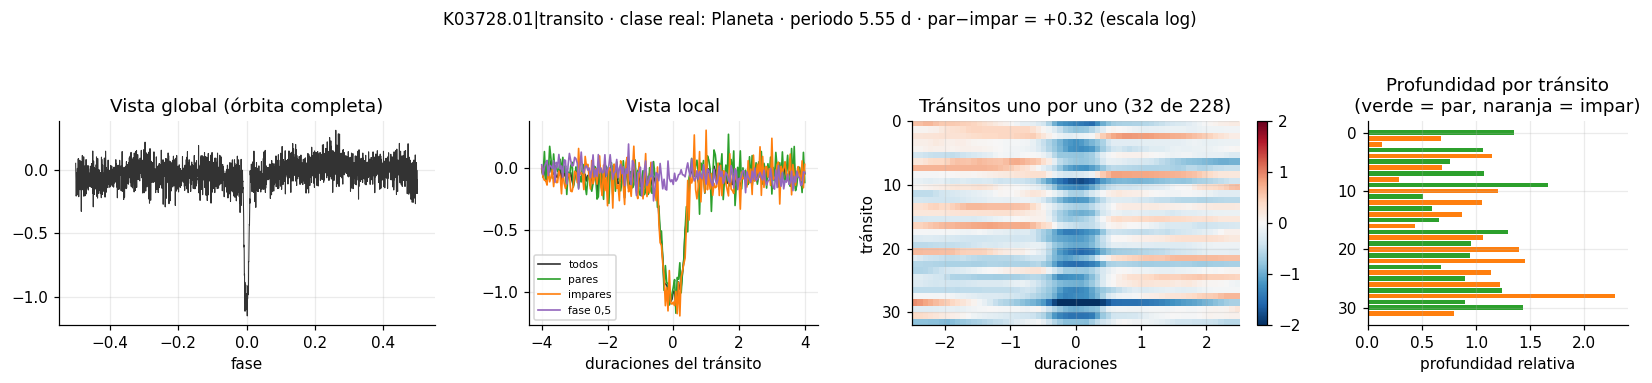

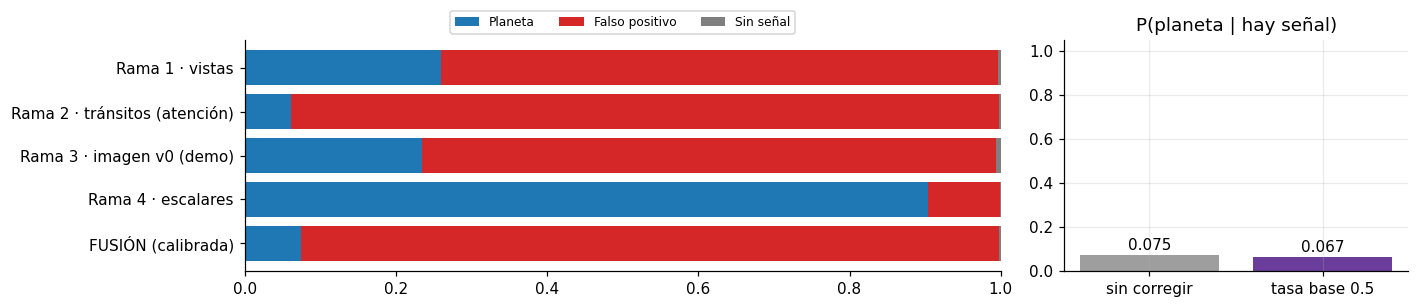

Real: Planeta · predicho por la fusión: Falso positivo ✗ ERROR · entropía 0.282 · desacuerdo entre cabezas 0.0141
Periodo 5.546 d · duración 2.72 h · profundidad medida 2273 ppm · SNR medido 56.7 · MES 154.7 · banderas del catálogo (solo informativas): nt=0 ss=1 co=0 ec=0


,id_ejemplo,clase_real,prediccion,p_planeta,p_fp,p_sin_senal,entropia,informacion_mutua,seleccion
0,K03728.01|transito,0,1,0.078,0.921,0.001,0.282,0.0141,error al azar
1,K07993.01|sin_senal,2,1,0.180,0.420,0.400,1.039,0.0098,error al azar
2,K00128.01|transito,0,1,0.197,0.803,0.000,0.497,0.0871,error al azar
3,K03216.01|transito,1,2,0.454,0.063,0.483,0.884,0.0984,error al azar
4,K06228.01|transito,0,1,0.165,0.448,0.388,1.024,0.1533,error al azar
5,K00191.01|transito,0,1,0.302,0.697,0.000,0.615,0.0830,error al azar
6,K00081.01|transito,1,0,0.897,0.102,0.000,0.334,0.0120,error al azar
7,K04929.01|transito,1,0,0.683,0.311,0.006,0.655,0.0790,error al azar
8,K05100.01|sin_senal,2,1,0.180,0.420,0.400,1.039,0.0098,error al azar
9,K00897.01|transito,0,1,0.473,0.526,0.001,0.696,0.0072,error al azar


In [15]:
explorar("K00022.01|transito", 0.5)
casos = pd.read_csv(R / "incertidumbre" / "casos_e11.csv"); explorar(casos[casos.seleccion == "error al azar"].id_ejemplo.iloc[0], 0.5)
display(casos)

## 8 · Veredicto de las hipótesis

El veredicto es **mecánico**: una hipótesis "se sostiene" solo si el intervalo del 95 % de la diferencia excluye el 0 en el sentido previsto. Se fijó así antes de ver los resultados.

,,hipotesis,pregunta,cantidad,estimacion,ic_inf,ic_sup,veredicto
0,·,P1a,¿La lectura tránsito por tránsito supera a la ...,AUC: rama 2 con atención − rama 1 (AstroNet),0.0189,-0.0247,0.0618,no se sostiene (el intervalo incluye el 0 o va...
1,·,P1b,¿La atención aporta frente al promedio?,AUC: atención − promedio,0.0202,-0.0138,0.0547,no se sostiene (el intervalo incluye el 0 o va...
2,·,P1c,¿La GRU supera a la atención?,AUC: GRU − atención,-0.0215,-0.0456,-0.0004,no se sostiene (el intervalo incluye el 0 o va...
3,✔,P2,¿La fusión supera a la mejor rama sola?,AUC: fusión − solo rama 4 (escalares),0.0315,0.0099,0.0570,se sostiene
4,✔,P2,¿Aporta la rama? (Sin rama 1 (vistas)),AUC: fusión − sin vistas,0.0072,0.0021,0.0138,se sostiene
5,·,P2,¿Aporta la rama? (Sin rama 2 (tránsitos)),AUC: fusión − sin transitos,0.0017,-0.0062,0.0096,no se sostiene (el intervalo incluye el 0 o va...
6,·,P2,¿Aporta la rama? (Sin rama 3 (imagen v0)),AUC: fusión − sin imagen,0.0038,-0.0033,0.0109,no se sostiene (el intervalo incluye el 0 o va...
7,✔,P2,¿Aporta la rama? (Sin rama 4 (escalares)),AUC: fusión − sin escalares,0.0160,0.0046,0.0306,se sostiene
8,✔,P2,¿La fusión supera a la demo vuelta a medir?,AUC: fusión − demo completa,0.0515,0.0270,0.0793,se sostiene
9,·,P3a,¿Mejora el NLL con temperature scaling?,NLL: después − antes,-0.0181,-0.0462,0.0008,no se sostiene (el intervalo incluye el 0 o va...


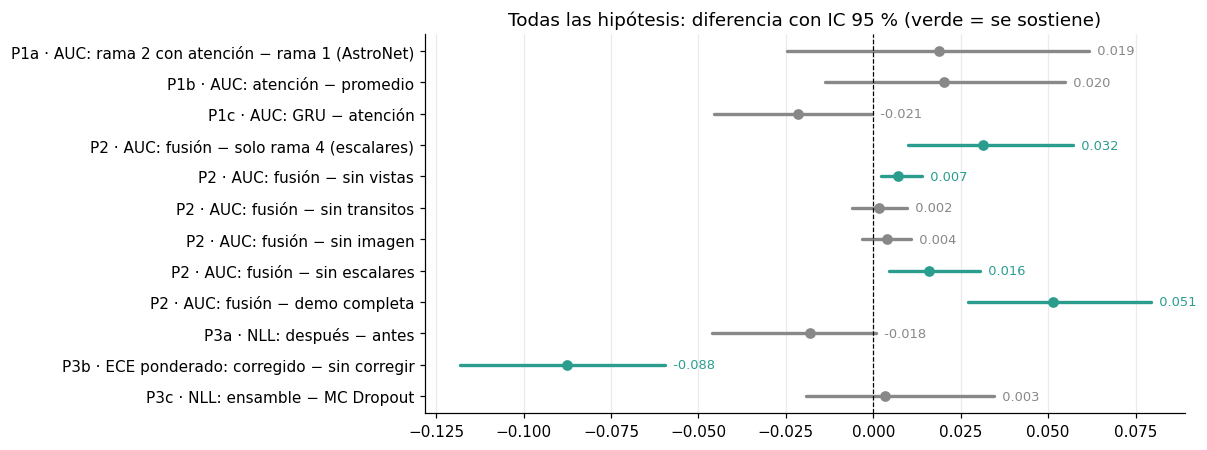

In [16]:
h = pd.read_csv(T / "resumen_hipotesis.csv")
h.insert(0, "", np.where(h.veredicto == "se sostiene", "✔", "·"))
try:
    def color(f): return ["background-color: #d8f0e6" if f.veredicto == "se sostiene" else "background-color: #f3f3f3"] * len(f)
    display(h.style.apply(color, axis=1).format({"estimacion": "{:+.4f}", "ic_inf": "{:+.4f}", "ic_sup": "{:+.4f}"}).hide(axis="index"))
except (AttributeError, ImportError):      # sin jinja2 no hay estilos: se muestra la tabla simple
    display(h.round(4))
fig, ax = plt.subplots(figsize=(11, 4.2))
bosque(ax, [f"{a} · {b}" for a, b in zip(h.hipotesis, h.cantidad)], h.estimacion, h.ic_inf, h.ic_sup, ["#2a9d8f" if v == "se sostiene" else "#888" for v in h.veredicto], ref=0)
ax.set_title("Todas las hipótesis: diferencia con IC 95 % (verde = se sostiene)"); plt.tight_layout(); plt.show()

### En una frase por pregunta

1. **Arquitectura.** La atención entre tránsitos fue la mejor rama temporal en promedio, pero su ventaja sobre el promedio simple y sobre la CNN de curva plegada **no se distingue de cero** en periodo corto. Solo supera de forma distinguible a la GRU.
2. **Fusión.** Unir las cuatro ramas **sí mejora** frente a cualquier rama sola y frente a la demo; queda **al nivel** del mejor modelo tabular con centroide, sin superarlo de forma demostrable.
3. **Calibración.** El sistema salió algo sobreconfiado; la temperatura lo corrige en la dirección esperada sin que la mejora sea distinguible. El **prior explícito sí funciona** de forma distinguible cuando la tasa base es baja. La incertidumbre **señala los errores**; MC Dropout y ensamble empatan.

### Limitaciones que hay que declarar

- **Periodo corto (1–30 días)**, con decenas o cientos de tránsitos: nada de esto permite concluir sobre el régimen de zona habitable.
- **245 señales**: los intervalos son anchos y varias diferencias reales pueden quedar ocultas.
- **Solo señales reales**, sin inyecciones ni falsas alarmas reconstruidas.
- La clase *sin señal* es construida; en ella el centroide siempre falta, lo que le da una pista fácil a la rama 4 (no afecta al AUC planeta vs FP).
- **Circularidad parcial**: parte de las etiquetas de falso positivo se asignaron con el centroide, que también es una entrada.
- **Apilado**: la cabeza de fusión quedó sobreconfiada; se midió y se corrigió con calibración.
- La **rama de imagen es la v0 de la demo** (224 de 245 estrellas tienen imagen); no es un aporte de este curso.
- La incertidumbre solo cubre la cabeza de fusión.
- 23 ejemplos no están disponibles en las ramas temporales (7 estrellas con menos de 4 trimestres y 9 ejemplos *sin señal* de binarias de duración muy larga).